In [1]:
import PyDSTool as dst
import numpy as np
from matplotlib import pyplot as plt

In [2]:
DSargs = dst.args(name="simple_Na_channel")

pars = {
    "g_na_bar": 1.0,
    "V0_m": -30.0,
    "V0_h": -50.0,
    "km": 8.0,
    "kh": 5.0,
    "V": 20.0  
}

fnspecs = {
    "m_inf": (['v'], "1 / (1 + exp(-(v - V0_m) / km))"),
    "h_inf": (['v'], "1 / (1 + exp((v - V0_h) / kh))") 
}

varspecs = {
    "m": "2 * (m_inf(V) - m)",
    "h": "0.2 * (h_inf(V) - h)"
}

ics = {
    "m": 1 / (1 + np.exp(-(-70.0 - pars["V0_m"]) / pars["km"])),
    "h": 1 / (1 + np.exp((-70.0 - pars["V0_h"]) / pars["kh"]))
}

DSargs.pars = pars
DSargs.fnspecs = fnspecs
DSargs.varspecs = varspecs
DSargs.ics = ics


Computing trajectory...


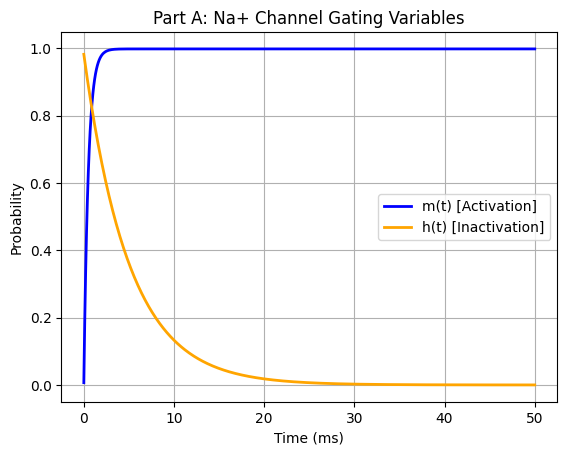

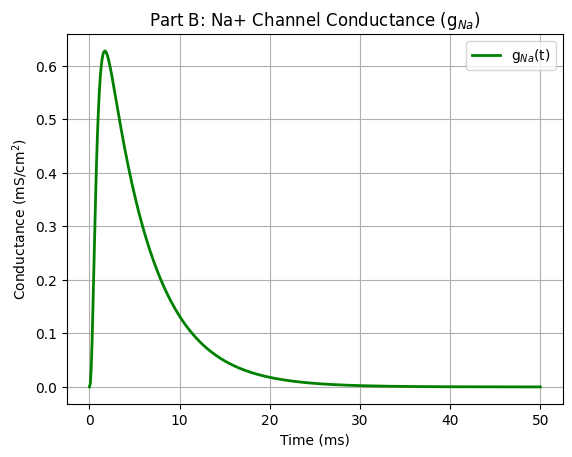

In [3]:
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

# Define time span
ode_sys.set(tdata=[0, 50])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample(dt=0.1)

# Plotting gating variables m(t) and h(t)
plt.figure()
plt.plot(points['t'], points['m'], label='m(t) [Activation]', color='blue', linewidth=2)
plt.plot(points['t'], points['h'], label='h(t) [Inactivation]', color='orange', linewidth=2)
plt.title('Part A: Na+ Channel Gating Variables')
plt.xlabel('Time (ms)')
plt.ylabel('Probability')
plt.legend()
plt.grid(True)
plt.show()

# Compute and plot Sodium Conductance: g_Na(t) = g_na_bar * m^3 * h
g_Na_t = pars['g_na_bar'] * (points['m']**3) * points['h']

plt.figure()
plt.plot(points['t'], g_Na_t, label='g$_{Na}$(t)', color='green', linewidth=2)
plt.title('Part B: Na+ Channel Conductance (g$_{Na}$)')
plt.xlabel('Time (ms)')
plt.ylabel('Conductance (mS/cm$^2$)')
plt.legend()
plt.grid(True)
plt.show()

The steady-state window current peaks at approximately: -30.7 mV
The window meaningfully exists between: -57.6 mV and 3.2 mV


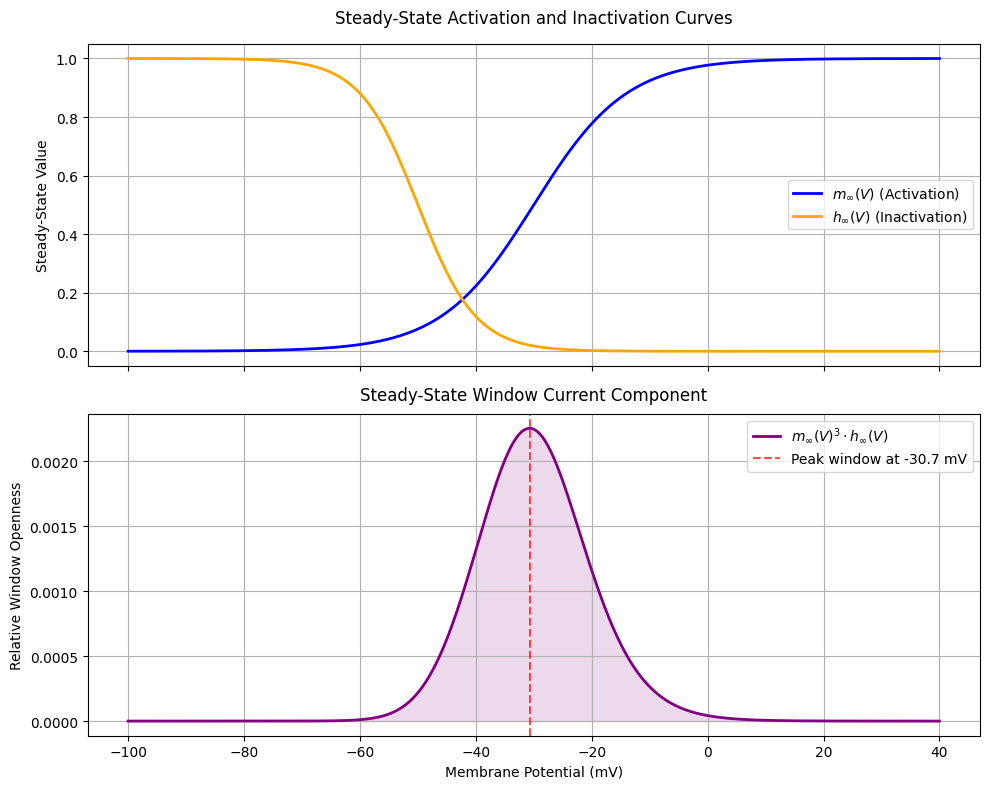

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# =====================================================================
# 0. Parameters (matching your previous PyDSTool model parameters)
# =====================================================================
V0_m = -30.0
V0_h = -50.0
km = 8.0
kh = 5.0

# Define the steady-state activation and inactivation functions
def m_inf(v):
    return 1 / (1 + np.exp(-(v - V0_m) / km))

def h_inf(v):
    return 1 / (1 + np.exp((v - V0_h) / kh))

# =====================================================================
# 1. Generate Voltage Range (-100 mV to 40 mV)
# =====================================================================
v_range = np.linspace(-100, 40, 500)

m_ss = m_inf(v_range)
h_ss = h_inf(v_range)
window_current_prop = (m_ss**3) * h_ss  # Proportional to steady-state window current

# Find the peak voltage for the window current to help identify the range
peak_idx = np.argmax(window_current_prop)
peak_v = v_range[peak_idx]
peak_val = window_current_prop[peak_idx]

# Threshold to define the "exist" range (e.g., where it is > 1% of its peak value)
threshold = 0.01 * peak_val
active_indices = np.where(window_current_prop > threshold)[0]
v_min, v_max = v_range[active_indices[0]], v_range[active_indices[-1]]

print(f"The steady-state window current peaks at approximately: {peak_v:.1f} mV")
print(f"The window meaningfully exists between: {v_min:.1f} mV and {v_max:.1f} mV")

# =====================================================================
# 2. Create the Two Subplots
# =====================================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Subplot 1: m_inf(V) and h_inf(V)
ax1.plot(v_range, m_ss, label=r'$m_{\infty}(V)$ (Activation)', color='blue', linewidth=2)
ax1.plot(v_range, h_ss, label=r'$h_{\infty}(V)$ (Inactivation)', color='orange', linewidth=2)
ax1.set_title('Steady-State Activation and Inactivation Curves', pad=15)
ax1.set_ylabel('Steady-State Value')
ax1.legend(loc='best')
ax1.grid(True)

# Subplot 2: m_inf(V)^3 * h_inf(V) (Window Current Proportionality)
ax2.plot(v_range, window_current_prop, label=r'$m_{\infty}(V)^3 \cdot h_{\infty}(V)$', color='purple', linewidth=2)
ax2.fill_between(v_range, window_current_prop, color='purple', alpha=0.15) # Visual shading for the window
ax2.axvline(peak_v, color='red', linestyle='--', alpha=0.7, label=f'Peak window at {peak_v:.1f} mV')

ax2.set_title('Steady-State Window Current Component', pad=10)
ax2.set_xlabel('Membrane Potential (mV)')
ax2.set_ylabel('Relative Window Openness')
ax2.legend(loc='best')
ax2.grid(True)

plt.tight_layout()
plt.show()


Computing trajectory...


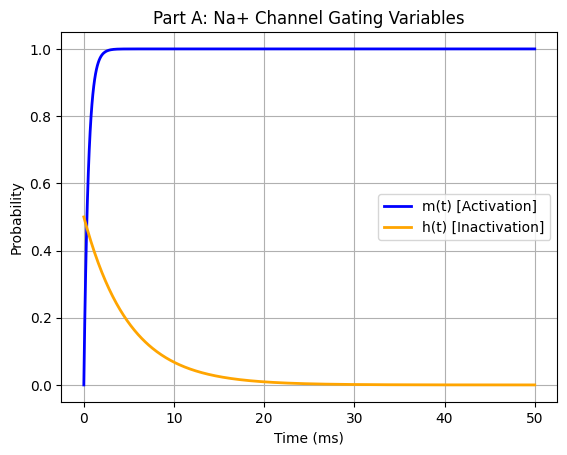

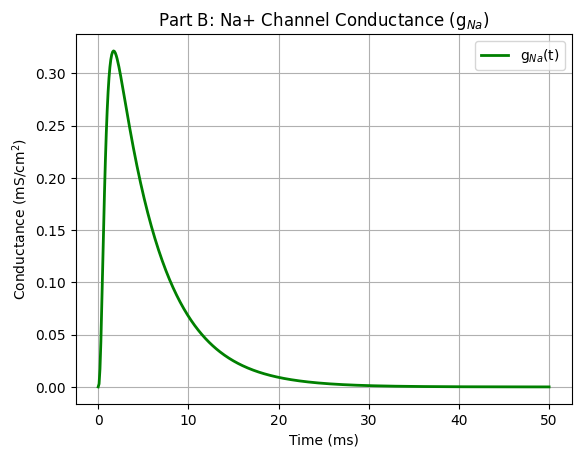

In [5]:
DSargs = dst.args(name="misaligned_na_channel")

pars = {
    "g_na_bar": 1.0,
    "V0_m": -30.0,
    "V0_h": -70.0,
    "km": 0.5,
    "kh": 5.0,
    "V": 20.0  
}

fnspecs = {
    "m_inf": (['v'], "1 / (1 + exp(-(v - V0_m) / km))"),
    "h_inf": (['v'], "1 / (1 + exp((v - V0_h) / kh))") 
}

varspecs = {
    "m": "2 * (m_inf(V) - m)",
    "h": "0.2 * (h_inf(V) - h)"
}

ics = {
    "m": 1 / (1 + np.exp(-(-70.0 - pars["V0_m"]) / pars["km"])),
    "h": 1 / (1 + np.exp((-70.0 - pars["V0_h"]) / pars["kh"]))
}

DSargs.pars = pars
DSargs.fnspecs = fnspecs
DSargs.varspecs = varspecs
DSargs.ics = ics

# ----

ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

# Define time span
ode_sys.set(tdata=[0, 50])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample(dt=0.1)

# Plotting gating variables m(t) and h(t)
plt.figure()
plt.plot(points['t'], points['m'], label='m(t) [Activation]', color='blue', linewidth=2)
plt.plot(points['t'], points['h'], label='h(t) [Inactivation]', color='orange', linewidth=2)
plt.title('Part A: Na+ Channel Gating Variables')
plt.xlabel('Time (ms)')
plt.ylabel('Probability')
plt.legend()
plt.grid(True)
plt.show()

# Compute and plot Sodium Conductance: g_Na(t) = g_na_bar * m^3 * h
g_Na_t = pars['g_na_bar'] * (points['m']**3) * points['h']

plt.figure()
plt.plot(points['t'], g_Na_t, label='g$_{Na}$(t)', color='green', linewidth=2)
plt.title('Part B: Na+ Channel Conductance (g$_{Na}$)')
plt.xlabel('Time (ms)')
plt.ylabel('Conductance (mS/cm$^2$)')
plt.legend()
plt.grid(True)
plt.show()
